# Task 3 milestone data exploration

GroupXXXXX. AI-assisted working notebook for team review, prepared 14 November 2026.

Uses the official Swedish development release only. Gold-label plots describe the released data. The single-cluster scorer check is a diagnostic, not the proposed model. No training, hidden test evaluation or competition submission is performed. Review the course AI policy before reusing code in assessed work.

## Setup and immutable input

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import json, hashlib, sys, random, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT = Path(__file__).resolve().parents[1] if '__file__' in globals() else Path.cwd().parent
RAW = ROOT / '04_data/raw/dev/SV'
OUT = ROOT / '04_data/processed'
FIG = ROOT / '08_figures'
OUT.mkdir(exist_ok=True, parents=True)
FIG.mkdir(exist_ok=True, parents=True)
def read_jsonl(path):
    return [json.loads(line) for line in path.read_text(encoding='utf-8').splitlines() if line.strip()]

usages = read_jsonl(RAW / 'usages.jsonl')
gold = read_jsonl(RAW / 'subtask1.jsonl')
df = pd.DataFrame(usages)
gf = pd.DataFrame(gold)
KEY = ['word', 'sentence_id']
assert not df.duplicated(KEY).any()
assert not gf.duplicated(KEY).any()
assert set(map(tuple, df[KEY].values)) == set(map(tuple, gf[KEY].values))
joined = df.merge(gf, on=KEY, suffixes=('', '_gold'), validate='one_to_one')
assert (joined.period_label == joined.period_label_gold).all()
assert all(isinstance(a, list) and a and all(type(x) is int for x in a) and len(a)==len(set(a)) for a in joined.label)
periods = sorted(df.period_label.unique(), key=lambda s: int(s.split('-')[0]))
words = sorted(df.word.unique())
print(f'Loaded {len(df):,} usages, {len(words)} words, {len(periods)} periods; language SV.')



Loaded 1,983 usages, 10 words, 10 periods; language SV.


## Data quality and source identity

In [2]:
required = ['word','sentence_id','text','pos','period_label','start','end','year']
missing = df[required].isna().sum().to_dict()
bad_offsets = [r['sentence_id'] for r in usages if not (type(r['start']) is int and type(r['end']) is int and 0 <= r['start'] < r['end'] <= len(r['text']))]
assert not bad_offsets
df['target_surface'] = [r['text'][r['start']:r['end']] for r in usages]
assert df.target_surface.str.strip().ne('').all()
df['whitespace_tokens'] = df.text.str.split().str.len()
df['characters'] = df.text.str.len()
duplicate_text = df[df.duplicated(['word','text'], keep=False)].sort_values(['word','text'])
duplicate_text.to_csv(OUT/'duplicate_text_review.csv',index=False)
period_year_mismatch = []
for r in usages:
    lo,hi=map(int,r['period_label'].split('-'))
    if not lo <= int(r['year']) <= hi:
        period_year_mismatch.append(r['sentence_id'])
audit = {'usages':len(df),'words':len(words),'periods':len(periods),'languages':['SV'],
 'missing_required_values':{k:int(v) for k,v in missing.items()},
 'duplicate_usage_keys':int(df.duplicated(KEY).sum()),'invalid_offsets':len(bad_offsets),
 'year_period_mismatches':len(period_year_mismatch),
 'duplicate_text_extra_rows':int(df.duplicated(['word','text']).sum()),
 'duplicate_text_rows_for_review':len(duplicate_text),
 'note':'Exact text repeats have distinct official IDs. Preserve all official usages. Surface forms may differ from lemmas due to inflection.',
 'files_sha256':{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in RAW.iterdir() if p.is_file()}}
(OUT/'quality_audit.json').write_text(json.dumps(audit,indent=2,ensure_ascii=False))
print(json.dumps({k:v for k,v in audit.items() if k!='files_sha256'},indent=2,ensure_ascii=False))



{
  "usages": 1983,
  "words": 10,
  "periods": 10,
  "languages": [
    "SV"
  ],
  "missing_required_values": {
    "word": 0,
    "sentence_id": 0,
    "text": 0,
    "pos": 0,
    "period_label": 0,
    "start": 0,
    "end": 0,
    "year": 0
  },
  "duplicate_usage_keys": 0,
  "invalid_offsets": 0,
  "year_period_mismatches": 0,
  "duplicate_text_extra_rows": 5,
  "duplicate_text_rows_for_review": 10,
  "note": "Exact text repeats have distinct official IDs. Preserve all official usages. Surface forms may differ from lemmas due to inflection."
}


## Coverage and annotation statistics

In [3]:
coverage=pd.crosstab(df.word,df.period_label).reindex(index=words,columns=periods,fill_value=0)
provided_counts=pd.read_csv(RAW/'usages_count.tsv',sep='\t').set_index('word').reindex(index=words,columns=periods)
assert (provided_counts==coverage).all().all()
provided_senses=pd.read_csv(RAW/'senses_count.tsv',sep='\t').set_index('word').reindex(index=words,columns=periods)
actual_senses=gf.groupby(['word','period_label']).label.apply(lambda groups:len({x for group in groups for x in group})).unstack(fill_value=0).reindex(index=words,columns=periods,fill_value=0)
sense_table_check={'usage_count_table_matches':True,'sense_table_cells_different_from_unique_gold_label_counts':int((provided_senses!=actual_senses).sum().sum()),'decision':'Compute sense counts from subtask1.jsonl. The auxiliary senses_count.tsv has an undocumented counting convention or stale values; do not treat it as unique gold senses.'}
(OUT/'auxiliary_table_check.json').write_text(json.dumps(sense_table_check,indent=2))
actual_senses.to_csv(OUT/'gold_unique_senses_by_period.csv')
print(json.dumps(sense_table_check,indent=2))
word_summary=[]
for word in words:
    d=df[df.word==word]; g=gf[gf.word==word]
    word_summary.append({'word':word,'usages':len(d),'observed_periods':int((coverage.loc[word]>0).sum()),
      'gold_senses':len({l for labels in g.label for l in labels}),
      'multi_label_usages':int(g.label.map(len).gt(1).sum()),
      'median_whitespace_tokens':float(d.whitespace_tokens.median())})
ws=pd.DataFrame(word_summary)
label_counts=gf.label.map(len).value_counts().sort_index()
summary={'usages':len(df),'words':len(words),'periods':periods,
 'word_summary':word_summary,'period_counts':{p:int(coverage[p].sum()) for p in periods},
 'label_cardinality_counts':{str(k):int(v) for k,v in label_counts.items()},
 'multi_label_usages':int(gf.label.map(len).gt(1).sum()),
 'multi_label_percentage':float(gf.label.map(len).gt(1).mean()*100),
 'whitespace_token_summary':{k:float(v) for k,v in df.whitespace_tokens.describe().items()},
 'observed_word_period_cells':int((coverage>0).sum().sum()),
 'empty_word_period_cells':int((coverage==0).sum().sum())}
coverage.to_csv(OUT/'word_period_counts.csv')
ws.to_csv(OUT/'word_summary.csv',index=False)
df.to_csv(OUT/'usages_with_descriptive_fields.csv',index=False)
pd.DataFrame({'period':periods,'usages':[summary['period_counts'][p] for p in periods]}).to_csv(OUT/'period_summary.csv',index=False)
(OUT/'eda_summary.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False))
print(ws.to_string(index=False))
print(f'Multiple labels: {summary["multi_label_usages"]}/{len(df)} = {summary["multi_label_percentage"]:.2f}%')



{
  "usage_count_table_matches": true,
  "sense_table_cells_different_from_unique_gold_label_counts": 69,
  "decision": "Compute sense counts from subtask1.jsonl. The auxiliary senses_count.tsv has an undocumented counting convention or stale values; do not treat it as unique gold senses."
}
     word  usages  observed_periods  gold_senses  multi_label_usages  median_whitespace_tokens
    dumpa     145                 5            6                  42                      26.0
exportera     149                 5            3                   0                      25.0
      fru     274                10            5                  79                      26.0
   fröken     174                10            4                   7                      32.0
   förort     150                 5            3                  79                      27.0
    herre     283                10            8                  42                      27.0
   kvinna     290                10       

## EDA figures

In [4]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.facecolor':'white'})
def save(fig,name):
    fig.savefig(FIG/(name+'.png'),dpi=180,bbox_inches='tight')
    fig.savefig(FIG/(name+'.svg'),bbox_inches='tight')
    plt.close(fig)

fig,ax=plt.subplots(figsize=(10.5,4.1))
im=ax.imshow(coverage.values,cmap='Blues',vmin=0,vmax=30,aspect='auto')
ax.set_xticks(range(len(periods)),periods,rotation=35,ha='right')
ax.set_yticks(range(len(words)),words)
for i in range(len(words)):
 for j in range(len(periods)):
    v=int(coverage.iloc[i,j]);ax.text(j,i,str(v),ha='center',va='center',color='white' if v>18 else '#18344b',fontsize=8)
fig.colorbar(im,ax=ax,label='Usages',shrink=.8)
ax.set_title('Word coverage across the official periods',loc='left',fontweight='bold',pad=12)
save(fig,'01_word_period_coverage')

fig,ax=plt.subplots(figsize=(9,3.6))
v=ws.sort_values('usages');ax.barh(v.word,v.usages,color='#1F607A')
for i,n in enumerate(v.usages):ax.text(n+3,i,str(n),va='center',fontsize=9)
ax.set_xlim(0,330);ax.set_xlabel('Usages');ax.set_title('Usage counts vary by target word',loc='left',fontweight='bold')
save(fig,'02_word_counts')

fig,axes=plt.subplots(1,2,figsize=(10.2,3.0))
axes[0].bar([str(x) for x in label_counts.index],label_counts.values,color=['#1F607A','#D28B45','#A04746'])
for i,n in enumerate(label_counts.values):axes[0].text(i,n+30,str(n),ha='center')
axes[0].set_ylim(0,2000);axes[0].set_xlabel('Gold labels per usage');axes[0].set_ylabel('Usages')
axes[0].set_title('262 usages have multiple labels',loc='left',fontweight='bold')
axes[1].hist(df.whitespace_tokens,bins=25,color='#1F607A',edgecolor='white')
axes[1].set_xlabel('Whitespace token count');axes[1].set_ylabel('Usages')
axes[1].set_title('Context length distribution',loc='left',fontweight='bold')
fig.tight_layout();save(fig,'03_labels_and_lengths')

# Gold distributions are descriptive EDA, never model predictions.
chosen='fru';labels=sorted({l for a in gf[gf.word==chosen].label for l in a})
counts=np.zeros((len(periods),len(labels)))
for r in gold:
 if r['word']==chosen:
  for label in r['label']:counts[periods.index(r['period_label']),labels.index(label)]+=1/len(r['label'])
props=counts/counts.sum(axis=1,keepdims=True)
fig,ax=plt.subplots(figsize=(10,3.4));bottom=np.zeros(len(periods))
colors=['#1F607A','#91B9C5','#D28B45','#C7C3B7','#7D6D95']
for j,l in enumerate(labels):
 ax.bar(periods,props[:,j],bottom=bottom,label=f'Gold sense {l}',color=colors[j%len(colors)]);bottom+=props[:,j]
ax.set_ylim(0,1);ax.set_ylabel('Fractional sense proportion');ax.tick_params(axis='x',rotation=35)
ax.legend(loc='upper left',bbox_to_anchor=(1,1),frameon=False)
ax.set_title('fru: observed gold sense proportions',loc='left',fontweight='bold')
save(fig,'04_gold_sense_distribution_fru')
print('Saved four chart figures as PNG and SVG.')



Saved four chart figures as PNG and SVG.


## Saved EDA figures

The final plot uses public gold labels and is descriptive EDA, not a model prediction.

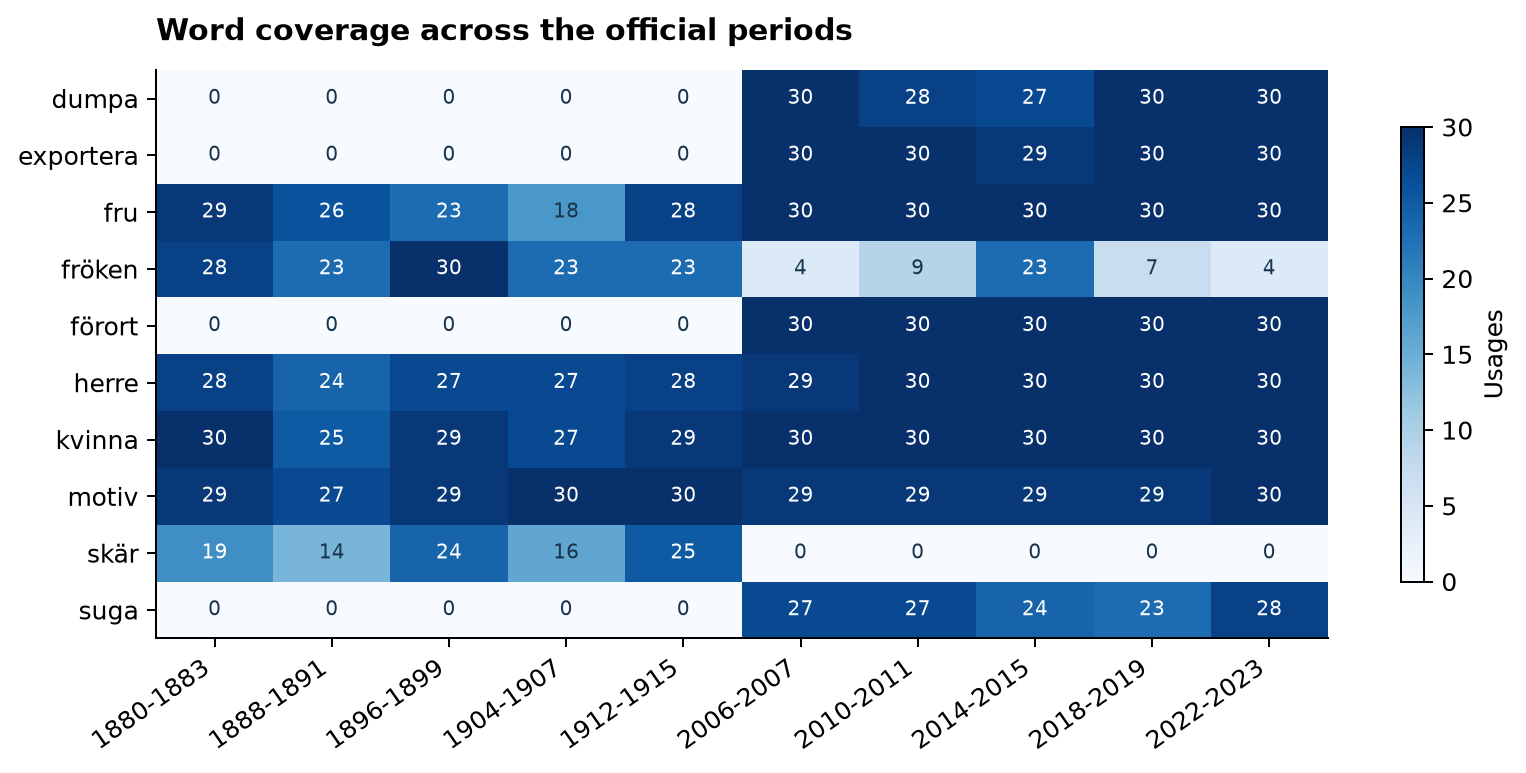

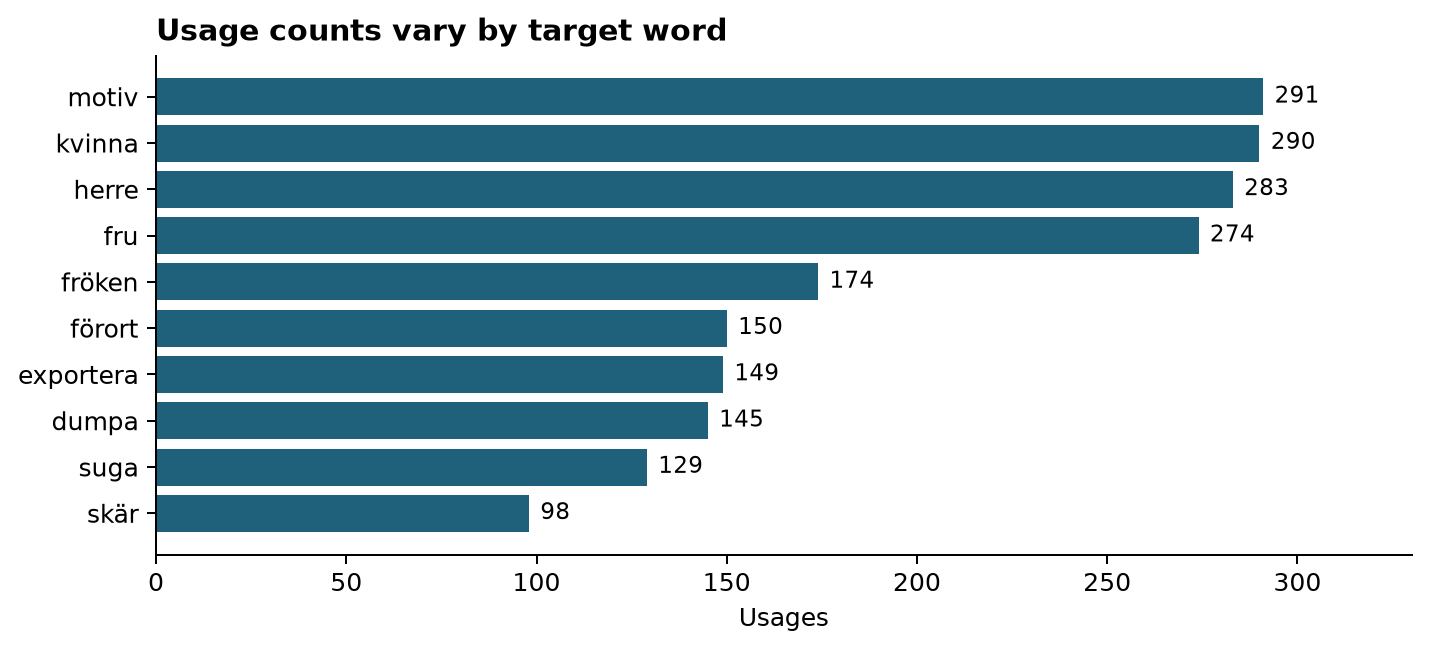

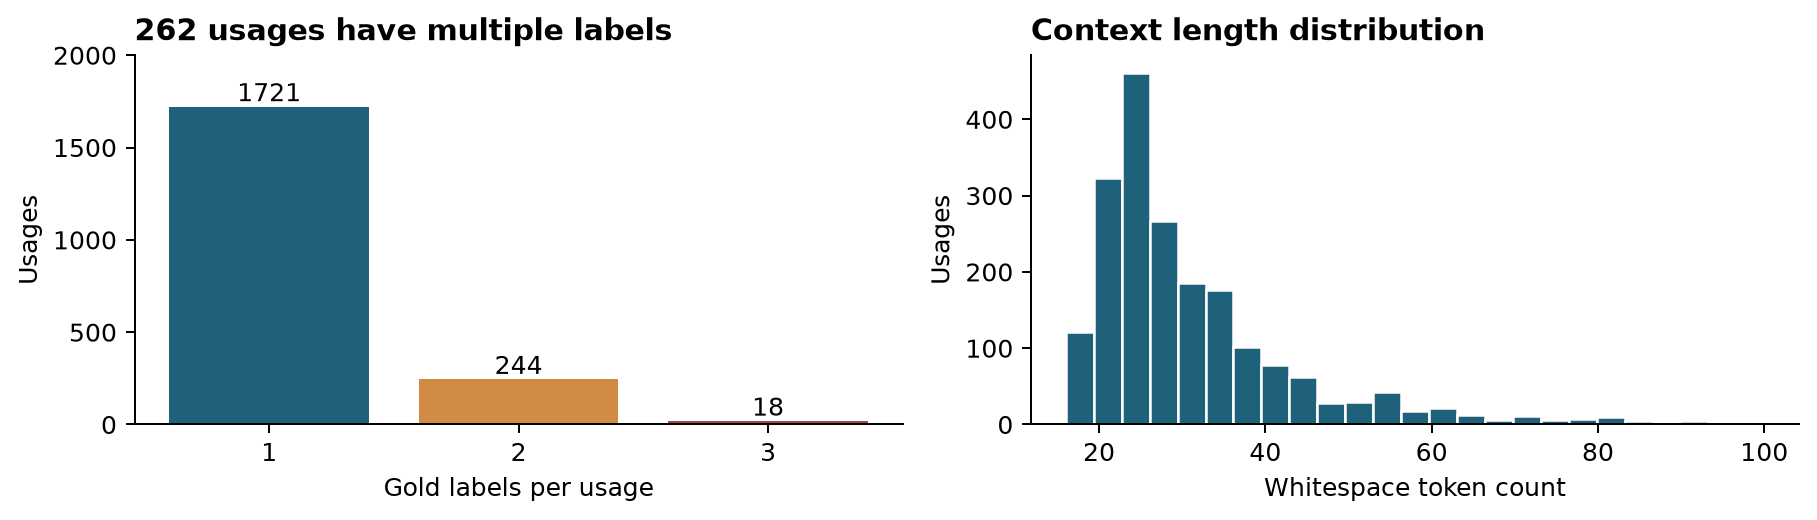

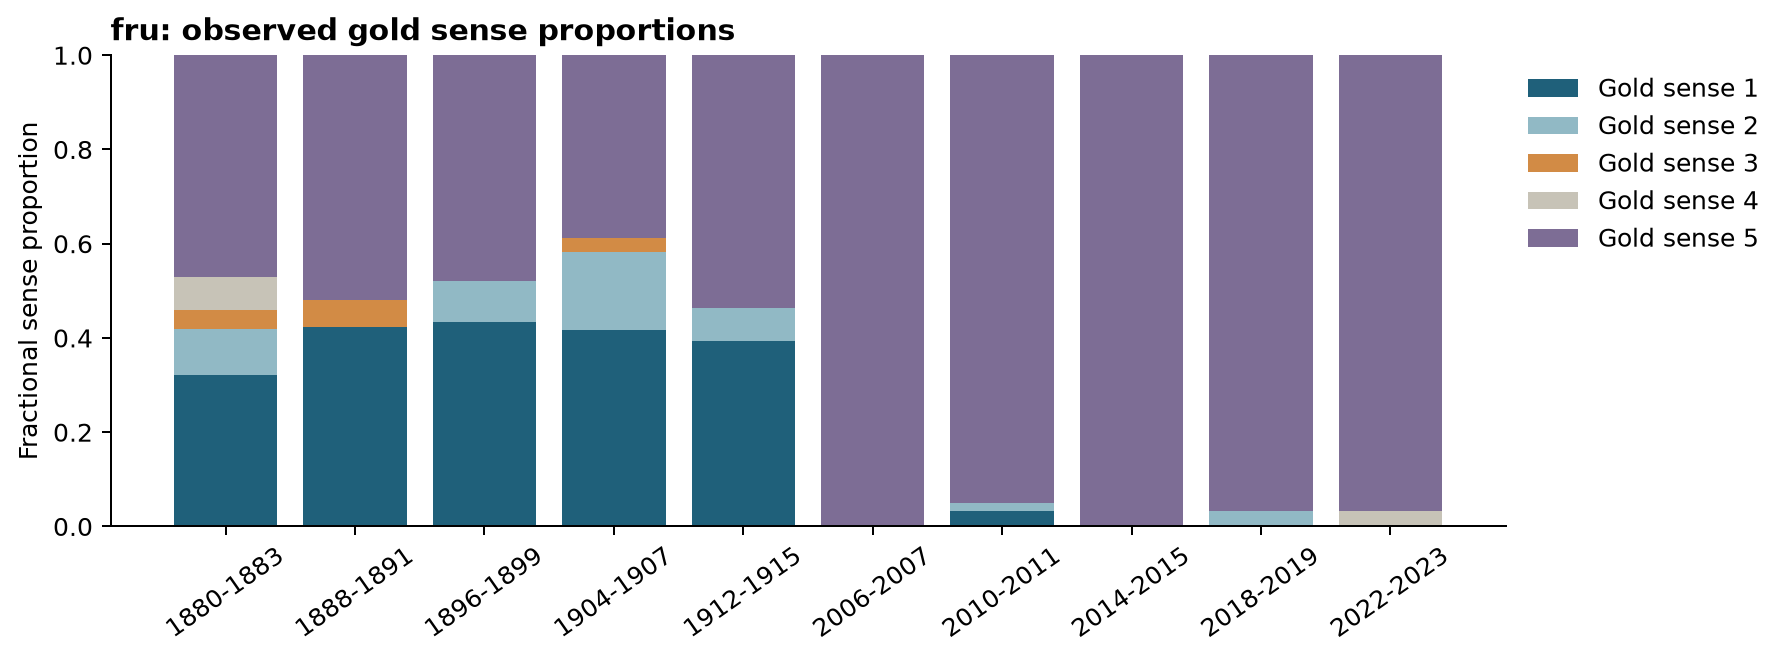

In [5]:
from IPython.display import display, Image
for name in ['01_word_period_coverage','02_word_counts','03_labels_and_lengths','04_gold_sense_distribution_fru']:
    display(Image(filename=str(FIG/(name+'.png'))))

## Proposed validation folds

In [6]:
# These are DEVELOPMENT folds. EDA has used all released words, so no pristine
# held-out test performance can be claimed. Each held-out word retains all periods.
shuffled=words.copy();random.Random(445).shuffle(shuffled)
folds=[]
for fold in range(5):
 held=shuffled[2*fold:2*fold+2]
 folds.append({'fold':fold+1,'tuning_words':[w for w in words if w not in held],
   'validation_words':held,'validation_usages':int(df.word.isin(held).sum())})
(OUT/'proposed_word_folds.json').write_text(json.dumps({'seed':445,'status':'proposed; not used for model tuning','folds':folds},indent=2,ensure_ascii=False))
print(json.dumps(folds,indent=2,ensure_ascii=False))



[
  {
    "fold": 1,
    "tuning_words": [
      "dumpa",
      "fru",
      "fröken",
      "förort",
      "herre",
      "kvinna",
      "motiv",
      "skär"
    ],
    "validation_words": [
      "suga",
      "exportera"
    ],
    "validation_usages": 278
  },
  {
    "fold": 2,
    "tuning_words": [
      "dumpa",
      "exportera",
      "fru",
      "fröken",
      "kvinna",
      "motiv",
      "skär",
      "suga"
    ],
    "validation_words": [
      "förort",
      "herre"
    ],
    "validation_usages": 433
  },
  {
    "fold": 3,
    "tuning_words": [
      "dumpa",
      "exportera",
      "fröken",
      "förort",
      "herre",
      "kvinna",
      "skär",
      "suga"
    ],
    "validation_words": [
      "fru",
      "motiv"
    ],
    "validation_usages": 565
  },
  {
    "fold": 4,
    "tuning_words": [
      "exportera",
      "fru",
      "förort",
      "herre",
      "kvinna",
      "motiv",
      "skär",
      "suga"
    ],
    "validation_words": [
     

## Official scorer integration diagnostic

In [7]:
# One cluster per word is a degenerate diagnostic, NOT the proposed semantic model.
# It never reads gold labels when generating predictions. No training or tuning.
sys.path.insert(0,str(ROOT/'07_sources/scorer'))
from evaluation import evaluate_subtask1, filter_jsd_by_min_instances
from evaluation_utils import load_subtask1_labels, calculate_JSD_distances
predictions=[{'word':r['word'],'sentence_id':r['sentence_id'],'label':[0]} for r in usages]
pred_path=OUT/'SV_subtask1_single_cluster.jsonl'
pred_path.write_text(''.join(json.dumps(r,ensure_ascii=False)+'\n' for r in predictions))
with zipfile.ZipFile(OUT/'single_cluster_format_example.zip','w',zipfile.ZIP_DEFLATED) as z:
 z.write(pred_path,arcname='SV_subtask1.jsonl')
with warnings.catch_warnings(record=True) as caught:
 warnings.simplefilter('always')
 result,rho=evaluate_subtask1(RAW/'subtask1.jsonl',pred_path)
pc,gc,pl,gl=load_subtask1_labels(pred_path,RAW/'subtask1.jsonl')
gold_distances=calculate_JSD_distances(gc)
filtered=filter_jsd_by_min_instances(gold_distances,gc,min_instances=10)
diagnostic={'description':'One cluster per word. Development integration diagnostic only; no semantic model training.',
 'subtask1a':result,'subtask1b_scorer_value':rho,
 'subtask1b_interpretation':'Predicted change scores are constant. Spearman correlation is mathematically undefined; the official scorer maps NaN to 0.',
 'candidate_period_pairs':len(gold_distances),'scored_period_pairs':len(filtered),
 'warnings':[str(w.message) for w in caught]}
(OUT/'scorer_diagnostic.json').write_text(json.dumps(diagnostic,indent=2))
pd.DataFrame([{'word_period_pair':k,'gold_js_distance':float(v),'included_in_1b':k in filtered} for k,v in gold_distances.items()]).to_csv(OUT/'gold_change_scores.csv',index=False)
print(json.dumps(diagnostic,indent=2))



{
  "description": "One cluster per word. Development integration diagnostic only; no semantic model training.",
  "subtask1a": {
    "precision": 0.6464234901205773,
    "recall": 0.9811562528047861,
    "fcubed": 0.7563415432223628
  },
  "subtask1b_scorer_value": 0,
  "subtask1b_interpretation": "Predicted change scores are constant. Spearman correlation is mathematically undefined; the official scorer maps NaN to 0.",
  "candidate_period_pairs": 65,
  "scored_period_pairs": 60,
  "warnings": [
    "An input array is constant; the correlation coefficient is not defined."
  ]
}


## Real input and output example

In [8]:
example=usages[0]
examples={'input':example,'target_surface':example['text'][example['start']:example['end']],
 'reference_labels':gold[0]['label'],
 'illustrative_prediction':{'word':example['word'],'sentence_id':example['sentence_id'],'label':[0]},
 'note':'Label 0 is an illustrative predicted cluster ID, not a semantic interpretation or a successful model prediction.'}
(OUT/'real_record_example.json').write_text(json.dumps(examples,ensure_ascii=False,indent=2))
print(json.dumps(examples,ensure_ascii=False,indent=2))
print('Milestone analysis complete. No evaluation-phase data downloaded or used.')


{
  "input": {
    "word": "kvinna",
    "sentence_id": "137d9286_62_69",
    "text": "nesliga lif medelst sjelfmord ; och ett stort antal olyckliga kvinnor , sorn sökt fly undan eländet , ha fallit i „mordeHglarnes4 händer , och deras ben vittra öfver allt i Utahs solbrända dalar .",
    "pos": "NN",
    "period_label": "1880-1883",
    "start": 62,
    "end": 69,
    "year": "1883"
  },
  "target_surface": "kvinnor",
  "reference_labels": [
    3
  ],
  "illustrative_prediction": {
    "word": "kvinna",
    "sentence_id": "137d9286_62_69",
    "label": [
      0
    ]
  },
  "note": "Label 0 is an illustrative predicted cluster ID, not a semantic interpretation or a successful model prediction."
}
Milestone analysis complete. No evaluation-phase data downloaded or used.
